# TS1 electrical portrait

This notebook builds the **reference model** of toric spine TS1: a 3D
finite-element (FEM) model of its interior on a tetrahedral mesh. It
places the spine's **25 real active zones (AZs)** and its **neck** on the
membrane, then asks two questions that decide what a reduced cable model of
TS1 must look like:

1. **How many compartments are needed at least?** (the rank bound)
2. **Do the holes matter electrically, or could a loop-free tree reproduce
   the spine?** (loopiness, via the four-point condition)

Everything is passive (leak + capacitance), with membrane in the
high-conductance (in vivo) state.

**Placeholders** (results that depend on them are marked):
- every AZ is a membrane patch of 0.05 µm² (PSD areas are not in the data);
- the neck joins a parent compartment of 80 MΩ and 100 pF (open question 4).

Results computed with the neck **clamped**, and all loopiness results, do
not depend on the parent values.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv

import camovox as cv
from camovox import ports, viz

pv.set_jupyter_backend("static")
SCALE = 0.005  # µm per pixel (all data files are in pixel coordinates)
rng = np.random.default_rng(0)

## 1. Mesh and FEM reference model

The closed surface of TS1 is filled with tetrahedra. With linear (P1)
elements, the FEM is an electrical network on the mesh vertices: interior
couplings come from the stiffness matrix, and each surface vertex carries
a share of the membrane.

What to check:
- **Area and volume change** measure how faithfully the tetrahedral mesh
  follows the original surface. Below 1% is good.
- **Negative couplings** come from badly shaped (obtuse) tetrahedra. The FEM
  answer is still accurate, but later reductions must tolerate them.

Meshing takes about 2 minutes the first time and is cached in
`../data/cache/` (delete the file to re-mesh with other settings).

In [2]:
mesh = cv.load_mesh("../data/TS1.obj", scale=SCALE)
tets, rep = cv.tetrahedralize_cached(
    mesh, "../data/cache/TS1_e0.2_env0.005.npz", edge_length=0.2, envelope=0.005
)
ref, q = cv.fem_model(tets)
surf = cv.MembraneSurface.from_model(tets, ref)
print(f"{rep.n_tets} tetrahedra, {ref.n_nodes} nodes")
print(f"membrane area {rep.area_out:.1f} µm² ({100 * rep.area_error:+.2f}%)")
print(f"volume {rep.volume_out:.2f} µm³ ({100 * rep.volume_error:+.2f}%)")
print(f"negative couplings: {100 * q.negative_fraction:.1f}% of total |κ|")

Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 elements to C_CONTIGUOUS.


134946 tetrahedra, 34128 nodes
membrane area 77.6 µm² (-0.80%)
volume 8.75 µm³ (-0.14%)
negative couplings: 4.8% of total |κ|


## 2. Sites: active zones and neck

AZ coordinates mark the presynaptic active zones, so they sit slightly
off the spine membrane (across the cleft). Each is **snapped** to the
nearest membrane vertex and grown into a geodesic patch of 0.05 µm². The
neck point becomes a larger patch (0.2 µm²) where the spine joins its
parent.

Colours give the presynaptic axon of each AZ (10 axons). The neck is −1.

AZ snap distance 0.025–0.100 µm


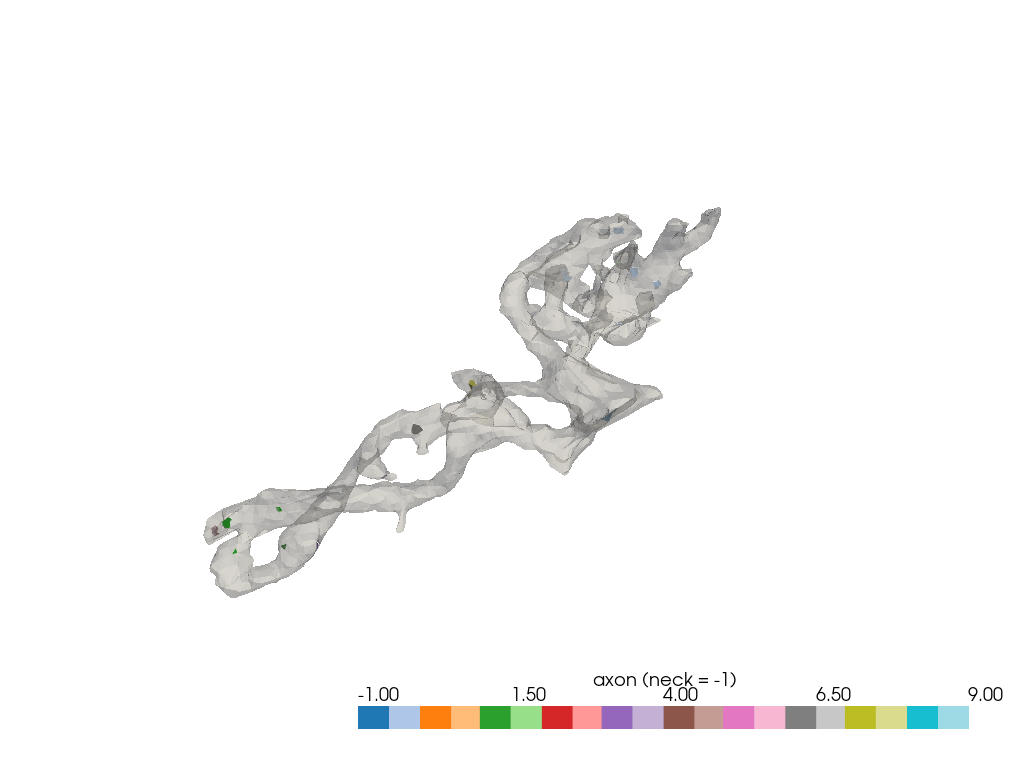

In [3]:
az = cv.sites_from_points(
    surf,
    cv.load_points("../data/TS1_AZ.txt", SCALE),
    "synapse",
    axon_groups=cv.load_axon_groups("../data/TS1_syn_axon_dist.txt"),
)
neck = cv.sites_from_points(
    surf, cv.load_points("../data/TS1_neckpoint.txt", SCALE), "neck", area=0.2
)
neck_xyz = neck.table[["x", "y", "z"]].to_numpy()
print(
    f"AZ snap distance {az.table.snap_distance.min():.3f}–"
    f"{az.table.snap_distance.max():.3f} µm"
)
axon = az.table.axon_id.to_numpy(dtype=float)
pl = viz.plot_sites(
    tets, az.patches + neck.patches, labels=[*axon, -1], name="axon (neck = -1)"
)
pl.show()

## 3. Port impedance matrix

The **ports** are the 25 AZ patches plus the neck (last row and column).
$Z_{ij}$ is the voltage at port i per unit current injected at port j:
- the **diagonal** $Z_{ii}$ is the input resistance at synapse i, which
  sets how big a local EPSP is;
- the **off-diagonals** $Z_{ij}$ are transfer resistances, which set how
  much one synapse depolarizes another (cross-talk);
- $Z_{i,\mathrm{neck}}$ is what reaches the parent.

**Neck clamped.** Holding the neck at rest (a Schur complement of Z)
removes the part every port shares through the parent and leaves the
spine's **own** internal structure. This is the part a reduced spine
model must reproduce, and it does not depend on the placeholder parent.

How to read the heat maps: bright blocks are groups of AZs that are
electrically close to each other (strong mutual cross-talk). A uniform
matrix would mean the spine acts as a single compartment.

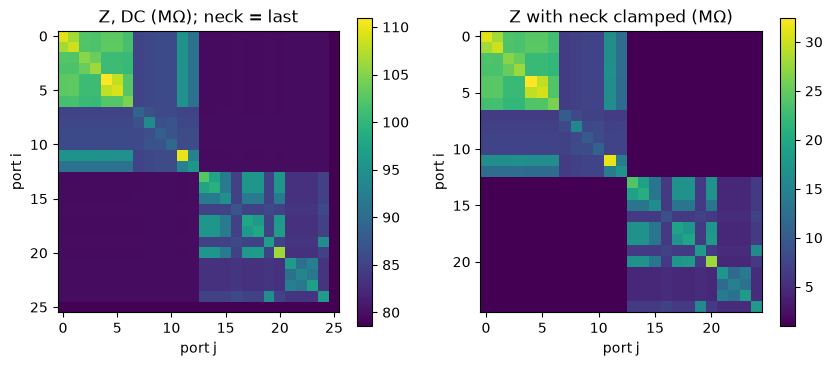

input resistance at AZs: 87.3–111.0 MΩ (placeholder)
spine-local resistance (neck clamped): 8.7–32.5 MΩ


In [4]:
p = cv.Passive(r_L=100.0, c_m=1.0, g_pas=2.63e-4)
spine = cv.attach_sink(ref, neck.patches[0], resistance=80e6, capacitance=100e-12)
freqs = [0.0, 100.0, 1000.0]
z = cv.port_impedance(spine, p, az.patches + neck.patches, freqs=freqs)
zdc = z[0].real
z_clamped = ports.clamp_port(zdc, len(zdc) - 1)

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
im = axs[0].imshow(zdc / 1e6, cmap="viridis")
axs[0].set_title("Z, DC (MΩ); neck = last")
fig.colorbar(im, ax=axs[0])
im = axs[1].imshow(z_clamped / 1e6, cmap="viridis")
axs[1].set_title("Z with neck clamped (MΩ)")
fig.colorbar(im, ax=axs[1])
for ax in axs:
    ax.set_xlabel("port j")
    ax.set_ylabel("port i")
plt.show()
zii, zloc = np.diag(zdc)[:-1] / 1e6, np.diag(z_clamped) / 1e6
print(f"input resistance at AZs: {zii.min():.1f}–{zii.max():.1f} MΩ (placeholder)")
print(f"spine-local resistance (neck clamped): {zloc.min():.1f}–{zloc.max():.1f} MΩ")

The spine-local resistance varies about 4× across the 25 synapses. Some
AZs sit close to the neck electrically, others behind thin loop arms. This
heterogeneity is what a single-compartment spine model would erase.

## 4. Voltage field from the most isolated AZ

10 pA into the AZ with the largest spine-local resistance. Where the
colour changes fastest is where the resistance is: thin necks and arms.
Nearly uniform colour over a region means that region is close to
isopotential and could be one compartment.

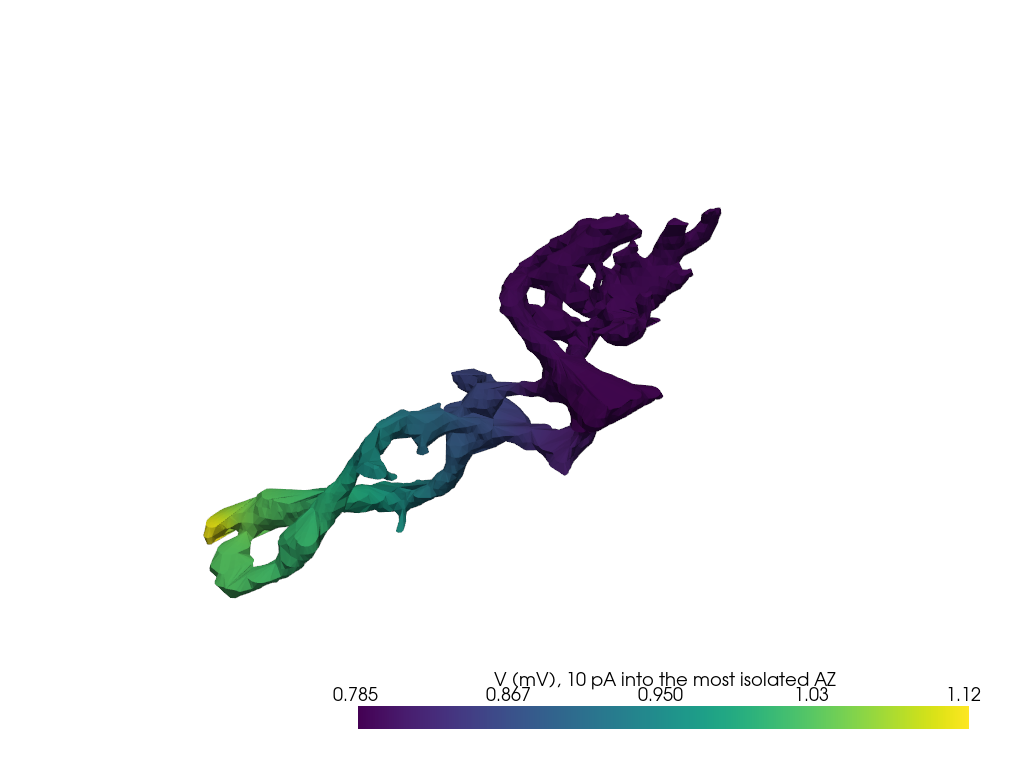

In [5]:
k = int(np.argmax(np.diag(z_clamped)))
w = az.patches[k]
v = cv.solve_dc(spine, p, 10e-12 * w / w.sum())
pl = viz.plot_surface(tets, 1e3 * v, name="V (mV), 10 pA into the most isolated AZ")
pl.show()

## 5. Rank bound: the fewest compartments for a given error

If every port of a reduced model sits on one of m compartments, its port
matrix has rank at most m. The best rank-m approximation of the FEM matrix
(from its singular values) therefore gives a **lower bound** on the error
of *any* such model, whatever its wiring. The curve shows that bound
(relative Frobenius error) against m.

How to read it:
- the m where the curve crosses your tolerance is a floor on the number of
  compartments that carry synapses;
- the clamped curve is the honest one for the spine's internal structure,
  because the full matrix is dominated by the shared parent;
- curves at 100 Hz and 1 kHz show whether faster signals need more
  structure.

**Caveat: this bound is pessimistic.** Each patch has its own spreading
resistance (current must fan out from a 0.05 µm² disk, about 2 MΩ). That
adds a diagonal, full-rank term. A reduced model captures it cheaply with
one small series resistance per synapse, not with extra compartments. A
"diagonal + low rank" bound would separate the two (next step).

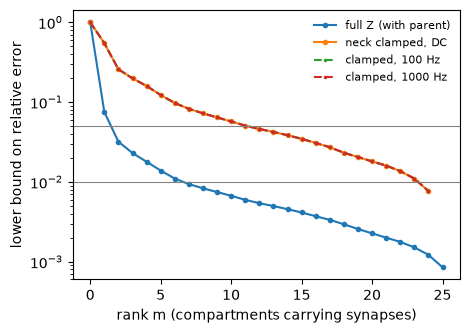

error ≤ 10% needs rank ≥ 6 (neck clamped)
error ≤ 5% needs rank ≥ 12 (neck clamped)
error ≤ 1% needs rank ≥ 24 (neck clamped)


In [6]:
fig, ax = plt.subplots(figsize=(5, 3.5))
for name, zz in [("full Z (with parent)", zdc), ("neck clamped, DC", z_clamped)]:
    err = ports.rank_bound(zz)
    ax.semilogy(np.arange(len(err) - 1), err[:-1], "o-", ms=3, label=name)
for f, zf in zip(freqs[1:], z[1:], strict=True):
    err = ports.rank_bound(ports.clamp_port(zf, len(zf) - 1))
    ax.semilogy(
        np.arange(len(err) - 1), err[:-1], ".--", ms=3, label=f"clamped, {f:g} Hz"
    )
for tol in (0.05, 0.01):
    ax.axhline(tol, color="gray", lw=0.8)
ax.set_xlabel("rank m (compartments carrying synapses)")
ax.set_ylabel("lower bound on relative error")
ax.legend(frameon=False, fontsize=8)
plt.show()
err_c = ports.rank_bound(z_clamped)
for tol in (0.1, 0.05, 0.01):
    print(
        f"error ≤ {tol:.0%} needs rank ≥ {int(np.argmax(err_c <= tol))} (neck clamped)"
    )

## 6. Loopiness: could a loop-free tree reproduce these ports?

**Resistance distance.** Remove the membrane, ground the neck, and define
$d_{ij} = R_{ii} + R_{jj} - 2R_{ij}$: the resistance you would measure
between ports i and j. It behaves like a distance (it obeys the triangle
inequality). The neck is port 0.

**Four-point condition.** Take any four ports and pair them up in the
three possible ways. Add the two distances in each pairing, giving three
sums. In a **tree** the two largest sums are always equal:

```
  i         k        d_ij + d_kl  = small (i,j and k,l on the same side)
   \       /         d_ik + d_jl  = large  } equal in a tree: both cross
    o-----o          d_il + d_jk  = large  } the middle path once
   /       \
  j         l
```

A loop gives current two routes, which shortens some distances but not
others, so the two largest sums come apart. A metric is reproducible by a
tree with internal nodes **if and only if** the two largest sums are equal
for every quadruple (Buneman 1974, the same test used for phylogenetic
trees).

For one quadruple, sort the three sums a ≥ b ≥ c. Two measures (see
notebook 01, section 5, for a worked ring example):

- **Relative violation** (a − b)/a: the error scale a tree must accept on
  these distances. 0 for a tree, 0.25 for four *points* evenly spaced on
  an ideal ring. This is the one that matters for **model accuracy**.
- **Intrinsic violation** (a − b)/(a − c): unchanged by adding resistance in
  series with any port. 0 for a tree, 1 for an ideal 4-port ring. This
  measures **topology**: is there loop structure at all, however weak?

Why both: current must fan out from each synapse patch (spreading
resistance, about 2 MΩ here). That adds the same amount to every distance
from that port, like a short leaf branch in a tree. Trees represent such
leaves for free, so it is right that they dilute the relative measure. But
they can hide loops that exist, and the intrinsic measure exposes those.

The **loopiness index** summarizes each measure over all C(26, 4) = 14,950
quadruples (mean, 90th percentile, max).

 relative: {'median': 0.0, 'p90': 0.0108, 'max': 0.0975, 'mean': 0.0035}
intrinsic: {'median': 0.0001, 'p90': 0.2113, 'max': 0.9133, 'mean': 0.0558}
absolute gap a − b: 90th pct 0.68 MΩ, max 4.46 MΩ
median port distance 27.8 MΩ
largest gap: ports [0, 7, 12, 13] (0 = neck), 4.46 MΩ


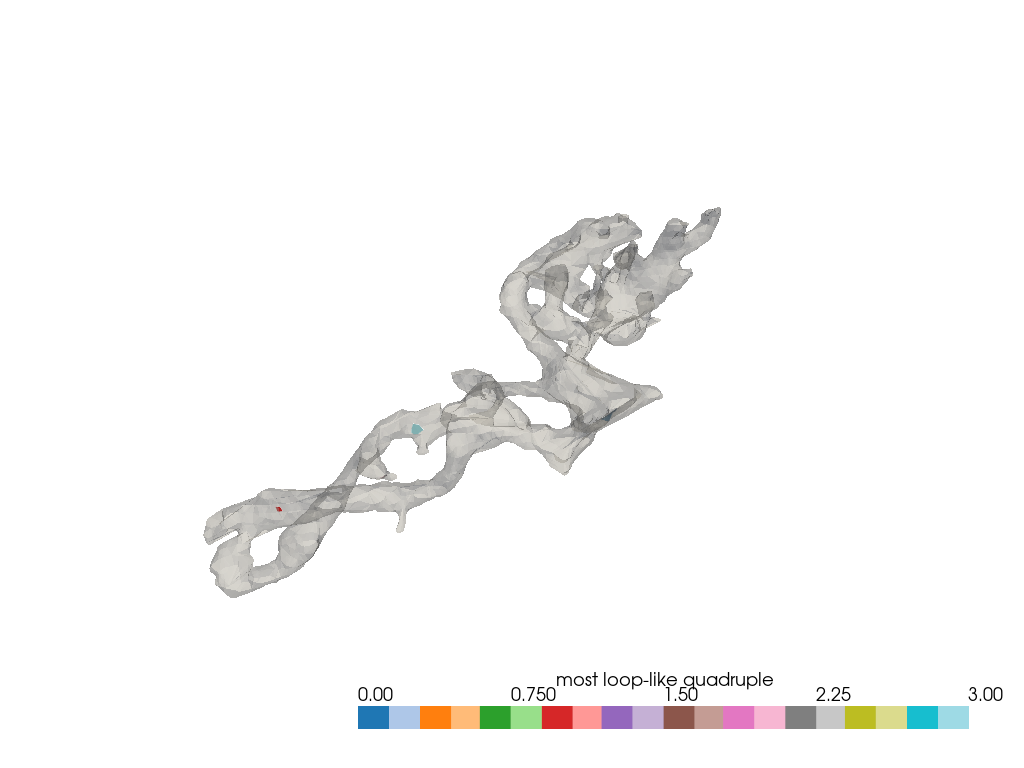

In [7]:
metric = ports.ResistanceMetric(ref, p, neck.patches[0])  # factorized once
d_real = metric.distances(az.patches)
measures = {"relative": "max", "intrinsic": "gap"}
li_real = {m: ports.loopiness_index(d_real, n) for m, n in measures.items()}
for m, li in li_real.items():
    print(f"{m:>9}:", {k_: round(v_, 4) for k_, v_ in li.items()})
gap_abs = ports.four_point_violation(d_real, "none")
upper = d_real[np.triu_indices(len(d_real), 1)]
g90, gmax, dmed = (
    np.quantile(gap_abs, 0.9) / 1e6,
    gap_abs.max() / 1e6,
    np.median(upper) / 1e6,
)
print(f"absolute gap a − b: 90th pct {g90:.2f} MΩ, max {gmax:.2f} MΩ")
print(f"median port distance {dmed:.1f} MΩ")

quads, vals = ports.worst_quadruples(d_real, k=1, normalize="none")
print(f"largest gap: ports {quads[0].tolist()} (0 = neck), {vals[0] / 1e6:.2f} MΩ")
worst = [neck.patches[0] if i == 0 else az.patches[i - 1] for i in quads[0]]
pl = viz.plot_sites(tets, worst, name="most loop-like quadruple")
pl.show()

The view above shows the four ports with the largest absolute gap, where a
tree would be most wrong. Expect them to straddle a hole, where current
has two comparable paths. Check this in the view rather than assuming it.

### Is the real placement special? Two null models

A low violation could be a property of TS1's shape (any synapses would
look tree-like) or of where the AZs sit. Two comparisons separate these:

- **Uniform re-draws**: 25 sites placed at random over the membrane (same
  patch area, at least 0.2 µm apart, at least 1 µm from the neck). Is the
  real placement unusually tree-like compared with random placement?
- **Jitter**: each real AZ moved randomly within a geodesic radius
  (0.25–2 µm). Does nudging the real AZs make things worse (real = a local
  optimum), or is the real value typical of its neighbourhood?

Read the **percentile**: the share of null draws with a violation at or
below the real one. Around 50% means typical. Below 5% would mean
significantly more tree-like than chance.

 relative mean: real 0.0035 | uniform median 0.0051, real at 15th pct | jitter pct 0.25 µm: 27, 0.5 µm: 47, 1 µm: 57, 2 µm: 33
 relative  p90: real 0.0108 | uniform median 0.0160, real at 10th pct | jitter pct 0.25 µm: 50, 0.5 µm: 43, 1 µm: 47, 2 µm: 40
 relative  max: real 0.0975 | uniform median 0.1371, real at 8th pct | jitter pct 0.25 µm: 47, 0.5 µm: 27, 1 µm: 17, 2 µm: 13
intrinsic mean: real 0.0558 | uniform median 0.0681, real at 20th pct | jitter pct 0.25 µm: 23, 0.5 µm: 17, 1 µm: 40, 2 µm: 50
intrinsic  p90: real 0.2113 | uniform median 0.2277, real at 34th pct | jitter pct 0.25 µm: 33, 0.5 µm: 27, 1 µm: 50, 2 µm: 70
intrinsic  max: real 0.9133 | uniform median 0.9950, real at 4th pct | jitter pct 0.25 µm: 13, 0.5 µm: 0, 1 µm: 7, 2 µm: 3


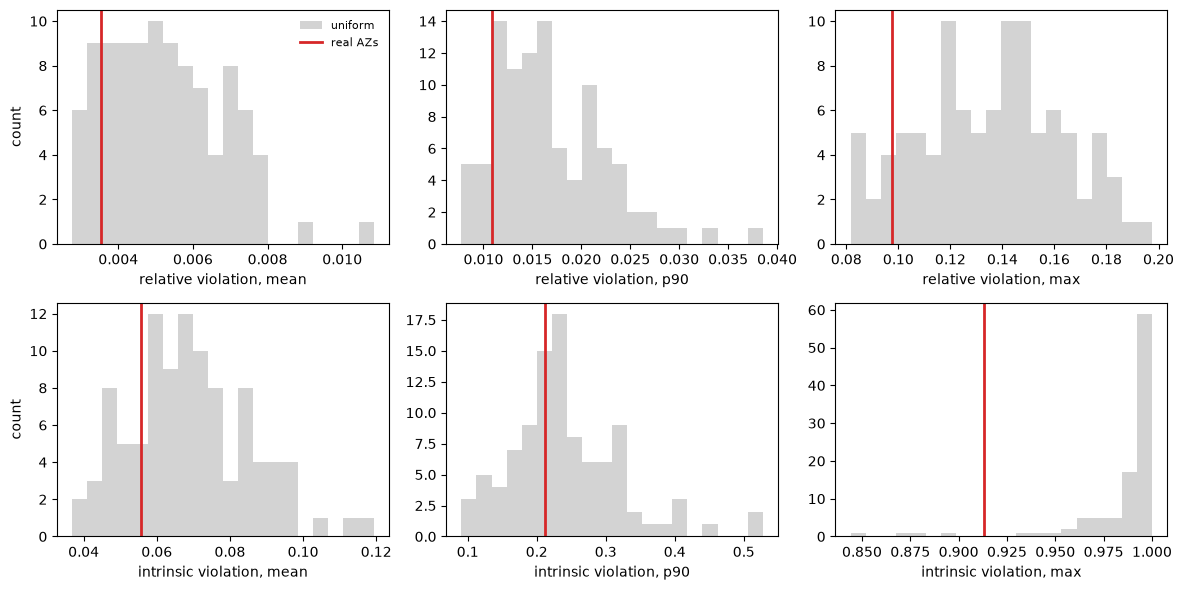

In [8]:
n_uniform = 100
d_uniform = []
for _ in range(n_uniform):
    u = cv.sample_uniform(
        surf, len(az), rng, min_spacing=0.2, exclude=neck_xyz, exclude_radius=1.0
    )
    d_uniform.append(metric.distances(u.patches))
radii = [0.25, 0.5, 1.0, 2.0]
d_jitter = {
    r: [metric.distances(cv.jitter_sites(surf, az, r, rng).patches) for _ in range(30)]
    for r in radii
}


def percentile(null: list[np.ndarray], measure: str, key: str) -> float:
    """Share of null draws at or below the real value, in %."""
    norm = measures[measure]
    real = li_real[measure][key]
    return 100 * np.mean([ports.loopiness_index(d, norm)[key] <= real for d in null])


for m, norm in measures.items():
    for key in ("mean", "p90", "max"):
        null = [ports.loopiness_index(d, norm)[key] for d in d_uniform]
        jit = ", ".join(
            f"{r:g} µm: {percentile(d_jitter[r], m, key):.0f}" for r in radii
        )
        print(
            f"{m:>9} {key:>4}: real {li_real[m][key]:.4f} | uniform median "
            f"{np.median(null):.4f}, real at {percentile(d_uniform, m, key):.0f}th pct"
            f" | jitter pct {jit}"
        )

fig, axs = plt.subplots(2, 3, figsize=(12, 6))
for row, (m, norm) in zip(axs, measures.items(), strict=True):
    for ax, key in zip(row, ["mean", "p90", "max"], strict=True):
        null = [ports.loopiness_index(d, norm)[key] for d in d_uniform]
        ax.hist(null, bins=20, color="lightgray", label="uniform")
        ax.axvline(li_real[m][key], color="C3", lw=2, label="real AZs")
        ax.set_xlabel(f"{m} violation, {key}")
    row[0].set_ylabel("count")
axs[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

### How to interpret this

- **The holes create real loop structure, but it is electrically weak.**
  The intrinsic measure reaches large values for some quadruples, so
  topologically there are loops between some synapses. But the absolute
  gaps (90th percentile below 1 MΩ, worst a few MΩ) are small next to the
  distances synapses see (median about 28 MΩ). The relative measure is
  therefore small: a tree with one leaf per synapse should reproduce TS1's
  port distances to about 1% typically and about 10% for the worst
  quadruple. That is good news for tree realization.
- **The real AZs are on the low side, but not significantly.** For the
  relative measure they land around the 8th–15th percentile of uniform
  draws. For the intrinsic measure they are typical of uniform draws. An
  earlier 20-draw comparison suggested that almost all random draws were
  higher, but that was small-sample noise. This is weak evidence at most
  that the AZ positions avoid loop-sensitive locations.
- **Jitter mostly does not make things worse.** Moving the real AZs by up
  to 2 µm gives values typical of the real configuration for every summary
  but one, so the real placement is not a finely tuned optimum in general.
- **One exception worth following up: the intrinsic maximum.** Almost
  every random or jittered site set contains one nearly perfect "ring"
  quadruple (intrinsic violation about 1). The real AZs don't (0.91: 4th
  percentile of uniform draws, 0–13th under jitter). In plain terms, the real
  synapses seem to avoid sitting as four evenly spread ports around a
  single hole. Treat this as a lead, not a result: a maximum is a fragile
  statistic, and the intrinsic ratio is unstable when its denominator is
  small. It needs the matched null below and the other spines.
- **Caveats:** the uniform null ignores the real AZs' spatial clustering
  (by axon and by region). Spacing is Euclidean, not geodesic. Patch area
  is a placeholder, and it sets the leaf terms that dilute the relative
  measure: smaller PSDs give larger leaves and more dilution. A stronger
  test would use a null matched to the real AZs' geodesic spacing and
  per-axon clustering.

## 7. Placement sensitivity of spine-local resistance

Same comparison for a quantity that matters directly for synaptic
responses: the spine-local input resistance at each synapse (neck
clamped). If real AZs sat at systematically more (or less) isolated
places than random sites, the two histograms would separate.

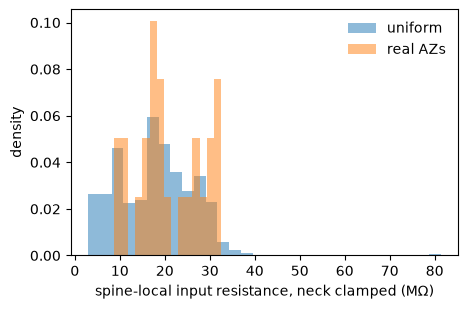

median local resistance: real 19.2 MΩ, uniform 18.1 MΩ


In [9]:
solver = cv.PortSolver(spine, p)  # factorized once
local_uniform = []
for _ in range(30):
    u = cv.sample_uniform(
        surf, len(az), rng, min_spacing=0.2, exclude=neck_xyz, exclude_radius=1.0
    )
    zu = solver.impedance(u.patches + neck.patches)
    local_uniform.append(np.diag(ports.clamp_port(zu, len(zu) - 1)))
local_uniform = np.concatenate(local_uniform) / 1e6
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.hist(local_uniform, bins=30, density=True, alpha=0.5, label="uniform")
ax.hist(zloc, bins=15, density=True, alpha=0.5, label="real AZs")
ax.set_xlabel("spine-local input resistance, neck clamped (MΩ)")
ax.set_ylabel("density")
ax.legend(frameon=False)
plt.show()
print(
    f"median local resistance: real {np.median(zloc):.1f} MΩ, "
    f"uniform {np.median(local_uniform):.1f} MΩ"
)

## Summary: what this says about a reduced TS1 model

- Synapses on TS1 are **electrically heterogeneous** (4× spread in local
  resistance), so one compartment is not enough when local voltages or
  cross-talk matter.
- The holes create genuine loop structure between some synapses, but it is
  **electrically weak**: a loop-free tree with one leaf per synapse plus
  internal branch points should reproduce the port distances to about 1%
  typically and about 10% at worst. The holes act mostly through the
  resistances they create, not through topology.
- The raw rank bound is high, but it is inflated by per-synapse spreading
  resistance. A diagonal + low-rank bound and an actual tree fit (next
  plan) will give the real compartment count.